# 1° COMPETENCIA DM EyF

##  1. Big Picture

LightGBM es el algoritmo estado del arte para datasets estructurados.
<br> La Bayesian Optimization es el estado del arte para optimización de hiperparámetros
<br> Las soluciones a las tres competencias de la asignatura contendrán LightGBMs y Bayesian Optimizations
<br> LightGBM ha aumentado en forma no darwiniana sus hiperparámetros en los últimos ocho años; no todos los existentes son útiles.
<br> Es necesario lograr entender cuales son los hiperparámetros relevantes de LightGBM

## 2. Hiperparámetros del LightGBM

Los objetivos de esta tarea son:


*   Aumentar la rentabilidad de la campaña de marketing de retención proactiva de clientes.
*   Generar un mejor modelo optimizando sus hiperparámetros
*   Conceptual : investigar los mas relevantes hiperparámetros de LightGBM
*   Familiarizarse con la Bayesian Optimization, sus largos tiempos de corrida y opciones para reducirlos
*   Familiarizarse con el uso de máquinas virtuales de Google Colab
*   Ver un pipeline completo de optimización de hiperparámetros y puesta en producción

LightGBM cuenta con mas de 60 hiperparámetros, siendo posible utilizar 40 al mismo tiempo, aunque no razonable.
<br> La documentación oficial de los hiperparámetros de LightGBM es  https://lightgbm.readthedocs.io/en/latest/Parameters.html#core-parameters


Se lo alerta sobre que una Optimizacion Bayesiana lleva varias horas de corrida, y usted deberá correr VARIAS optimizaciones para descubrir cuales parámetros conviene optimizar.
<br> A pesar que la próxima clase es recien en viernes 01 de agosto, inicie la tarea con tiempo, aprenda a planificar estratégicamente sus corridas como un@ científ@  de datos.

Es necesario investigar cuales son los hiperparámetros de LightGBM que vale la pena optimizar en una Bayesian Optimization, ya que los realmente utiles son apenas un reducido subconjunto.
<br>Usted deberá investigar cuales son los hiperparámetros mas relevantes de LightGBM, su primer alternativa es preguntándole a su amigo con capacidades especiales ChatGPT o sus endogámicos familiares Claude, DeepSeek, Gemini, Grok, etc
<br> La segunda alternativa es la propia documentación de LightGBM  https://lightgbm.readthedocs.io/en/latest/Parameters-Tuning.html


Adicionalmente podra buscar información como la que proveen esta diminuta muestra aleatoria de artículos ligeros:
*  https://medium.com/@sarahzouinina/a-deep-dive-into-lightgbm-how-to-choose-and-tune-parameters-7c584945842e
*  https://www.kaggle.com/code/somang1418/tuning-hyperparameters-under-10-minutes-lgbm
*  https://towardsdatascience.com/beginners-guide-to-the-must-know-lightgbm-hyperparameters-a0005a812702/


<br>  La muestra anterior se brinda a modo de ejemplo, usted deberá buscar muuuuchas  fuentes adicionales de información
<br> Tenga presente que LightGBM es el estado del arte en modelado predictivo para datasets estructurado, que son el 90% del trabajo del 95% de los Data Scientists en Argentina.

#### 2.1  Seteo del ambiente en Google Colab

Esta parte se debe correr con el runtime en Python3
<br>Ir al menu, Runtime -> Change Runtime Type -> Runtime type ->  **Python 3**

Conectar la virtual machine donde esta corriendo Google Colab con el  Google Drive, para poder tener persistencia de archivos

In [ ]:
# primero establecer el Runtime de Python 3
from google.colab import drive
drive.mount('/content/.drive')

Mounted at /content/.drive


Para correr la siguiente celda es fundamental en Arranque en Frio haber copiado el archivo kaggle.json al Google Drive, en la carpeta indicada en el instructivo

<br>los siguientes comando estan en shell script de Linux
*   Crear las carpetas en el Google Drive
*   "instalar" el archivo kaggle.json desde el Google Drive a la virtual machine para que pueda ser utilizado por la libreria  kaggle de Python
*   Bajar el  **dataset_pequeno**  al  Google Drive  y tambien al disco local de la virtual machine que esta corriendo Google Colab



In [ ]:
%%shell

mkdir -p "/content/.drive/My Drive/dmeyf"
mkdir -p "/content/buckets"
ln -s "/content/.drive/My Drive/dmeyf" /content/buckets/b1


mkdir -p /content/buckets/b1/exp
mkdir -p /content/buckets/b1/datasets
mkdir -p /content/datasets



archivo_origen="https://storage.googleapis.com/open-courses/dmeyf2026-9c6f/competencia_01_crudo.csv"
archivo_destino="/content/datasets/competencia_01_crudo.csv"
archivo_destino_bucket="/content/buckets/b1/datasets/competencia_01_crudo.csv"

if ! test -f $archivo_destino_bucket; then
  wget  $archivo_origen  -O $archivo_destino_bucket
fi


if ! test -f $archivo_destino; then
  cp  $archivo_destino_bucket  $archivo_destino
fi


DELTA LAGS 1 y 2

In [ ]:
require("data.table")

dataset <- fread("/content/datasets/competencia_01_crudo.csv")

# Calcular la clase_ternaria
dsimple <- dataset[, list(
    "pos" = .I,
    numero_de_cliente,
    periodo0 = as.integer(foto_mes/100)*12 + foto_mes%%100 ) ]

setorder(dsimple, numero_de_cliente, periodo0)

periodo_ultimo <- dsimple[, max(periodo0)]
periodo_anteultimo <- periodo_ultimo - 1

dsimple[, c("periodo1", "periodo2") :=
    shift(periodo0, n=1:2, fill=NA, type="lead"), numero_de_cliente]

dsimple[periodo0 < periodo_anteultimo, clase_ternaria := "CONTINUA"]

dsimple[periodo0 < periodo_ultimo &
    (is.na(periodo1) | periodo0 + 1 < periodo1),
    clase_ternaria := "BAJA+1"]

dsimple[periodo0 < periodo_anteultimo & (periodo0+1 == periodo1)
    & (is.na(periodo2) | periodo0 + 2 < periodo2),
    clase_ternaria := "BAJA+2"]

setorder(dsimple, pos)
dataset[, clase_ternaria := dsimple$clase_ternaria]
rm(dsimple)

# DELTA LAG1 Y DELTA LAG2
setorder(dataset, numero_de_cliente, foto_mes)

cols_id <- c("numero_de_cliente", "foto_mes", "clase_ternaria")
cols_features <- setdiff(colnames(dataset), cols_id)

cols_deltas_lag1 <- paste0("d_", cols_features, "_lag1")
cols_deltas_lag2 <- paste0("d_", cols_features, "_lag2")

dataset[, (cols_deltas_lag1) := .SD - shift(.SD, n = 1, type = "lag"),
        .SDcols = cols_features]

es_nuevo_cliente_1 <- dataset$numero_de_cliente != shift(dataset$numero_de_cliente, n = 1, type = "lag")
es_nuevo_cliente_1[1] <- TRUE
dataset[es_nuevo_cliente_1, (cols_deltas_lag1) := NA]


dataset[, (cols_deltas_lag2) := .SD - shift(.SD, n = 2, type = "lag"),
        .SDcols = cols_features]

es_nuevo_cliente_2 <- dataset$numero_de_cliente != shift(dataset$numero_de_cliente, n = 2, type = "lag")
es_nuevo_cliente_2[1:2] <- TRUE
dataset[es_nuevo_cliente_1 | es_nuevo_cliente_2, (cols_deltas_lag2) := NA]

# Limpiar variables auxiliares
rm(es_nuevo_cliente_1, es_nuevo_cliente_2)

# Guardar
fwrite(dataset, file = "/content/datasets/competencia_01.csv.gz", sep = ",")

cat("Proceso completado. Total de columnas guardadas:", ncol(dataset), "\n")

Loading required package: data.table


Attaching package: ‘data.table’


The following object is masked from ‘package:base’:

    %notin%




Proceso completado. Total de columnas guardadas: 459 


## Generacion de la clase_ternaria

Esta parte se debe correr con el runtime en lenguaje **R** Ir al menu, Runtime -> Change Runtime Tipe -> Runtime type -> R

In [ ]:
setorder( dataset, foto_mes, clase_ternaria, numero_de_cliente)
dataset[, .N, list(foto_mes, clase_ternaria)]

foto_mes,clase_ternaria,N
<int>,<chr>,<int>
202103,BAJA+1,1019
202103,BAJA+2,960
202103,CONTINUA,160921
202104,BAJA+1,964
202104,BAJA+2,1139
202104,CONTINUA,161181
202105,BAJA+1,1143
202105,BAJA+2,870
202105,CONTINUA,161755


### 2.2 Optimizacion Hiperparámetros

Esta parte se debe correr con el runtime en lenguaje R Ir al menu, Runtime -> Change Runtime Type -> Runtime type -> R

### 2.2.1 Inicio

limpio el ambiente de R

In [ ]:
format(Sys.time(), "%a %b %d %X %Y")

[1] "Sat Oct 10 09:15:26 PM 2026"

In [ ]:
# limpio la memoria
rm(list=ls(all.names=TRUE)) # remove all objects
gc(full=TRUE, verbose=FALSE) # garbage collection

,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,745004,39.8,1473300,78.7,1473300,78.7
Vcells,1399477,10.7,522525072,3986.6,653152979,4983.2


### 2.2.2 Carga de Librerias

Esta parte lleva varios minutos la primera vez en Google Colab

In [ ]:
# cargo las librerias que necesito
require("data.table")
require("parallel")

if(!require("R.utils")) install.packages("R.utils")
require("R.utils")

if( !require("primes") ) install.packages("primes")
require("primes")

if( !require("utils") ) install.packages("utils")
require("utils")

if( !require("rlist") ) install.packages("rlist")
require("rlist")

if( !require("yaml")) install.packages("yaml")
require("yaml")

if( !require("lightgbm") ) install.packages("lightgbm")
require("lightgbm")

if( !require("DiceKriging") ) install.packages("DiceKriging")
require("DiceKriging")

if( !require("mlrMBO") ) install.packages("mlrMBO")
require("mlrMBO")

Loading required package: parallel

Loading required package: R.utils

Warning message in library(package, lib.loc = lib.loc, character.only = TRUE, logical.return = TRUE, :
“there is no package called ‘R.utils’”
Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘R.oo’, ‘R.methodsS3’


Loading required package: R.utils

Loading required package: R.oo

Loading required package: R.methodsS3

R.methodsS3 v1.8.2 (2022-06-13 22:00:14 UTC) successfully loaded. See ?R.methodsS3 for help.

R.oo v1.27.1 (2025-05-02 21:00:05 UTC) successfully loaded. See ?R.oo for help.


Attaching package: ‘R.oo’


The following object is masked from ‘package:R.methodsS3’:

    throw


The following objects are masked from ‘package:methods’:

    getClasses, getMethods


The following objects are masked from ‘package:base’:

    attach, detach, load, save


R.utils v2.13.0 (2025-02-24 21:20:02 UTC) successfully loaded. See ?R.utils for help.


At

### 2.2.3 Definicion de Parametros

aqui debe cargar SU semilla primigenia
<br>recuerde cambiar el numero de experimento en cada corrida nueva

In [ ]:
###CAMBIAR NRO DE EXPERIMENTO###
PARAM <- list()
PARAM$experimento <- 4992
PARAM$semilla_primigenia <- 137363


In [ ]:
# training y future
PARAM$train <- c(202103, 202104, 202105, 202106)
PARAM$train_final <- c(202103, 202104, 202105, 202106)
PARAM$future <- c(202108)
PARAM$semilla_kaggle <- 314159
PARAM$cortes <- seq(4000, 19000, by= 500)

In [ ]:
# un undersampling de 0.1  toma solo el 10% de los CONTINUA
# undersampling de 1.0  implica tomar TODOS los datos

PARAM$trainingstrategy$undersampling <- 0.2

In [ ]:
# Parametros LightGBM

PARAM$hyperparametertuning$xval_folds <- 5

# parametros fijos del LightGBM que se pisaran con la parte variable de la BO
PARAM$lgbm$param_fijos <- list(
  boosting = "gbdt",
  objective = "binary",
  metric = "auc",
  first_metric_only = FALSE,
  boost_from_average = TRUE,
  feature_pre_filter = FALSE,
  force_row_wise = TRUE,
  verbosity = -100,

  seed = PARAM$semilla_primigenia,

  max_depth = -1L, # -1 significa no limitar
  min_gain_to_split = 0,
  min_sum_hessian_in_leaf = 0.001,
  lambda_l1 = 0.0,
  lambda_l2 = 0.0,
  max_bin = 31L, # Fijo, no participa de la BO

  bagging_fraction = 1.0,
  pos_bagging_fraction = 1.0,
  neg_bagging_fraction = 1.0,
  is_unbalance = FALSE,
  scale_pos_weight = 1.0,

  drop_rate = 0.1,
  max_drop = 50,
  skip_drop = 0.5,

  extra_trees = FALSE, # Cambiar a TRUE si deseas probar la variante Extra Trees

  # Valores por defecto de resguardo (se sobreescriben en cada iteración de la BO)
  num_iterations = 600,
  learning_rate = 0.03,
  feature_fraction = 0.50,
  num_leaves = 256,
  min_data_in_leaf = 1000
)


Aqui se definen los hiperparámetros de LightGBM que participan de la Bayesian Optimization
<br> si es un numero entero debe ir  makeIntegerParam
<br> si es un numero real (con decimales) debe ir  makeNumericParam
<br> es muy importante leer cuales son un lower y upper  permitidos y ademas razonables

In [ ]:
#Límites acotados de los árboles
PARAM$hypeparametertuning$hs <- makeParamSet(
  makeIntegerParam("num_iterations", lower = 200L, upper = 600L),
  makeNumericParam("learning_rate", lower = 0.02, upper = 0.10),
  makeNumericParam("feature_fraction", lower = 0.20, upper = 0.70),
  makeIntegerParam("num_leaves", lower = 32L, upper = 256L),
  makeIntegerParam("min_data_in_leaf", lower = 500L, upper = 4000L)
)

A mayor cantidad de hiperparámetros, se debe aumentar las iteraciones de la Bayesian Optimization
<br> 30 es un valor muy tacaño, pero corre rápido
<br> deberia partir de 50, alcanzando los 100 si se dispone de tiempo

In [ ]:
PARAM$hyperparametertuning$iteraciones <- 20 # iteraciones bayesianas

In [ ]:
# particionar agrega una columna llamada fold a un dataset
#   que consiste en una particion estratificada segun agrupa
# particionar( data=dataset, division=c(70,30),
#  agrupa=clase_ternaria, seed=semilla)   crea una particion 70, 30

particionar <- function(data, division, agrupa= "", campo= "fold", start= 1, seed= NA) {
  if (!is.na(seed)) set.seed(seed, "L'Ecuyer-CMRG")

  bloque <- unlist(mapply(
    function(x, y) {rep(y, x)},division, seq(from= start, length.out= length(division))))

  data[, (campo) := sample(rep(bloque,ceiling(.N / length(bloque))))[1:.N],by= agrupa]
}

In [ ]:
# iniciliazo el dataset de realidad, para medir ganancia
realidad_inicializar <- function( pfuture, pparam) {

  # datos para verificar la ganancia
  drealidad <- pfuture[, list(numero_de_cliente, foto_mes, clase_ternaria)]

  particionar(drealidad,
    division= c(3, 7),
    agrupa= "clase_ternaria",
    seed= PARAM$semilla_kaggle
  )

  return( drealidad )
}

In [ ]:
# evaluo ganancia en los datos de la realidad

realidad_evaluar <- function( prealidad, pprediccion) {

  prealidad[ pprediccion,
    on= c("numero_de_cliente", "foto_mes"),
    predicted:= i.Predicted
  ]

  tbl <- prealidad[, list("qty"=.N), list(fold, predicted, clase_ternaria)]

  res <- list()
  res$public  <- tbl[fold==1 & predicted==1L, sum(qty*ifelse(clase_ternaria=="BAJA+2", 1072500, -27500))]/0.3
  res$private <- tbl[fold==2 & predicted==1L, sum(qty*ifelse(clase_ternaria=="BAJA+2", 1072500, -27500))]/0.7
  res$total <- tbl[predicted==1L, sum(qty*ifelse(clase_ternaria=="BAJA+2", 1072500, -27500))]

  prealidad[, predicted:=NULL]
  return( res )
}

### 2.2.4  Preprocesamiento

In [ ]:
# carpeta de trabajo

setwd("/content/buckets/b1/exp")
experimento_folder <- paste0("HT", PARAM$experimento)
dir.create(experimento_folder, showWarnings=FALSE)
setwd( paste0("/content/buckets/b1/exp/", experimento_folder ))

In [ ]:
# lectura del dataset
dataset <- fread("/content/datasets/competencia_01.csv.gz", stringsAsFactors= TRUE)

In [ ]:
dataset_train <- dataset[foto_mes %in% PARAM$train]

In [ ]:
# paso la clase a binaria que tome valores {0,1}  enteros
#  BAJA+1 y BAJA+2  son  1,   CONTINUA es 0
#  a partir de ahora ya NO puedo cortar  por prob(BAJA+2) > 1/40

dataset_train[,
  clase01 := ifelse(clase_ternaria %in% c("BAJA+2","BAJA+1"), 1L, 0L)
]

In [ ]:
# defino los datos que forma parte del training
# aqui se hace el undersampling de los CONTINUA
# notar que para esto utilizo la SEGUNDA semilla

set.seed(PARAM$semilla_primigenia, kind = "L'Ecuyer-CMRG")
dataset_train[, azar := runif(nrow(dataset_train))]
dataset_train[, training := 0L]

dataset_train[
  foto_mes %in%  PARAM$train &
    (azar <= PARAM$trainingstrategy$undersampling | clase_ternaria %in% c("BAJA+1", "BAJA+2")),
  training := 1L
]

In [ ]:
###¿El ID de los clientes?
# los campos que se van a utilizar

campos_buenos <- setdiff(
  colnames(dataset_train),
  c("clase_ternaria", "clase01", "azar", "training")
)

In [ ]:
# dejo los datos en el formato que necesita LightGBM

dtrain <- lgb.Dataset(
  data= data.matrix(dataset_train[training == 1L, campos_buenos, with= FALSE]),
  label= dataset_train[training == 1L, clase01],
  free_raw_data= FALSE
)

nrow(dtrain)
ncol(dtrain)

[1] 137113

[1] 458

2.2.5 Configuracion Bayesian Optimization

In [ ]:
# En el argumento x llegan los parmaetros de la bayesiana
#  devuelve la AUC en cross validation del modelo entrenado

EstimarGanancia_AUC_lightgbm <- function(x) {

  # x pisa (o agrega) a param_fijos
  param_completo <- modifyList(PARAM$lgbm$param_fijos, x)

  # entreno LightGBM
  modelocv <- lgb.cv(
    data= dtrain,
    nfold= PARAM$hyperparametertuning$xval_folds,
    stratified= TRUE,
    param= param_completo
  )

  # obtengo la ganancia
  AUC <- modelocv$best_score

  # hago espacio en la memoria
  rm(modelocv)
  gc(full= TRUE, verbose= FALSE)

  message(format(Sys.time(), "%a %b %d %X %Y"), " AUC ", AUC)

  return(AUC)
}

In [ ]:
# Aqui comienza la configuracion de la Bayesian Optimization

# en este archivo quedan la evolucion binaria de la BO
kbayesiana <- "bayesiana.RDATA"

funcion_optimizar <- EstimarGanancia_AUC_lightgbm # la funcion que voy a maximizar

configureMlr(show.learner.output= FALSE)

# configuro la busqueda bayesiana,  los hiperparametros que se van a optimizar
# por favor, no desesperarse por lo complejo

obj.fun <- makeSingleObjectiveFunction(
  fn= funcion_optimizar, # la funcion que voy a maximizar
  minimize= FALSE, # estoy Maximizando la ganancia
  noisy= TRUE,
  par.set= PARAM$hypeparametertuning$hs, # definido al comienzo del programa
  has.simple.signature= FALSE # paso los parametros en una lista
)

# cada 300 segundos guardo el resultado intermedio
ctrl <- makeMBOControl(
  save.on.disk.at.time= 300, # se graba cada 300 segundos
  save.file.path= kbayesiana
) # se graba cada 300 segundos

# indico la cantidad de iteraciones que va a tener la Bayesian Optimization
ctrl <- setMBOControlTermination(
  ctrl,
  iters= PARAM$hyperparametertuning$iteraciones
) # cantidad de iteraciones

# defino el método estandar para la creacion de los puntos iniciales,
# los "No Inteligentes"
ctrl <- setMBOControlInfill(ctrl, crit= makeMBOInfillCritEI())

# establezco la funcion que busca el maximo
surr.km <- makeLearner(
  "regr.km",
  predict.type= "se",
  covtype= "matern3_2",
  control= list(trace= TRUE)
)


2.2.6 Corrida Bayesian Optimization

In [ ]:

# inicio la optimizacion bayesiana, retomando si ya existe
# es la celda mas lenta de todo el notebook

if (!file.exists(kbayesiana)) {
  bayesiana_salida <- mbo(obj.fun, learner= surr.km, control= ctrl)
} else {
  bayesiana_salida <- mboContinue(kbayesiana) # retomo en caso que ya exista
}

Warning message in mboContinue(kbayesiana):
“Tuning ended with term.iter. No need to continue. Simply returning stored result.”


In [ ]:

tb_bayesiana <- as.data.table(bayesiana_salida$opt.path)
colnames( tb_bayesiana)

[1] "num_iterations"   "learning_rate"    "feature_fraction" "num_leaves"      
 [5] "min_data_in_leaf" "y"                "dob"              "eol"             
 [9] "error.message"    "exec.time"        "ei"               "error.model"     
[13] "train.time"       "prop.type"        "propose.time"     "se"              
[17] "mean"

In [ ]:
# almaceno los resultados de la Bayesian Optimization
# y capturo los mejores hiperparametros encontrados

tb_bayesiana <- as.data.table(bayesiana_salida$opt.path)

tb_bayesiana[, iter := .I]

# ordeno en forma descendente por AUC = y
setorder(tb_bayesiana, -y)

# grabo para eventualmente poder utilizarlos en OTRA corrida
fwrite( tb_bayesiana,
  file= "BO_log.txt",
  sep= "\t"
)

# los mejores hiperparámetros son los que quedaron en el registro 1 de la tabla
PARAM$out$lgbm$mejores_hiperparametros <- tb_bayesiana[
  1, # el primero es el de mejor AUC
  setdiff(colnames(tb_bayesiana),
    c("y","dob","eol","error.message","exec.time","ei","error.model",
      "train.time","prop.type","propose.time","se","mean","iter")),
  with= FALSE
]


PARAM$out$lgbm$y <- tb_bayesiana[1, y]


In [ ]:
write_yaml( PARAM, file="PARAM.yml")

In [ ]:
print(PARAM$out$lgbm$mejores_hiperparametros)
print(PARAM$out$lgbm$y)

   num_iterations learning_rate feature_fraction num_leaves min_data_in_leaf
            <int>         <num>            <num>      <int>            <int>
1:            590    0.04982431        0.5267277        256              501
[1] 0.9384878


## 2.3  Produccion

### Final Training
Construyo el modelo final, que es uno solo, no hace ningun tipo de particion < training, validation, testing>]

In [ ]:
setwd("/content/buckets/b1/exp")
experimento <- paste0("exp", PARAM$experimento)
dir.create(experimento, showWarnings= FALSE)
setwd( paste0("/content/buckets/b1/exp/", experimento ))

#### Final Training Dataset

Aqui esta la gran decision de en qué meses hago el Final Training
<br> debo utilizar los mejores hiperparámetros que encontré en la  optimización bayesiana

In [ ]:
# clase01
dataset[, clase01 := ifelse(clase_ternaria %in% c("BAJA+1", "BAJA+2"), 1L, 0L)]

In [ ]:
dataset_train <- dataset[foto_mes %in% PARAM$train_final]
dataset_train[,.N,clase_ternaria]

clase_ternaria,N
<fct>,<int>
CONTINUA,645999
BAJA+2,4067
BAJA+1,4000


In [ ]:
# dejo los datos en el formato que necesita LightGBM

dtrain_final <- lgb.Dataset(
  data= data.matrix(dataset_train[, campos_buenos, with= FALSE]),
  label= dataset_train[, clase01]
)

#### Final Training Hyperparameters

In [ ]:
param_final <- modifyList(PARAM$lgbm$param_fijos,
  PARAM$out$lgbm$mejores_hiperparametros)

param_final

$boosting
[1] "gbdt"

$objective
[1] "binary"

$metric
[1] "auc"

$first_metric_only
[1] FALSE

$boost_from_average
[1] TRUE

$feature_pre_filter
[1] FALSE

$force_row_wise
[1] TRUE

$verbosity
[1] -100

$seed
[1] 137363

$max_depth
[1] -1

$min_gain_to_split
[1] 0

$min_sum_hessian_in_leaf
[1] 0.001

$lambda_l1
[1] 0

$lambda_l2
[1] 0

$max_bin
[1] 31

$bagging_fraction
[1] 1

$pos_bagging_fraction
[1] 1

$neg_bagging_fraction
[1] 1

$is_unbalance
[1] FALSE

$scale_pos_weight
[1] 1

$drop_rate
[1] 0.1

$max_drop
[1] 50

$skip_drop
[1] 0.5

$extra_trees
[1] FALSE

$num_iterations
[1] 590

$learning_rate
[1] 0.04982431

$feature_fraction
[1] 0.5267277

$num_leaves
[1] 256

$min_data_in_leaf
[1] 501

#### Training
Genero el modelo final, siempre sobre TODOS los datos de  final_train, sin hacer ningun tipo de undersampling de la clase mayoritaria y mucho menos cross validation.

In [ ]:
# este punto es muy SUTIL  y será revisado en la Clase 05

param_normalizado <- copy(param_final)
param_normalizado$min_data_in_leaf <-  round(param_final$min_data_in_leaf / PARAM$trainingstrategy$undersampling)

In [ ]:
# entreno LightGBM

modelo_final <- lgb.train(
  data= dtrain_final,
  param= param_normalizado
)

In [ ]:
# ahora imprimo la importancia de variables

tb_importancia <- as.data.table(lgb.importance(modelo_final))
archivo_importancia <- "impo.txt"

fwrite(tb_importancia,
  file= archivo_importancia,
  sep= "\t"
)

In [ ]:
# grabo a disco el modelo en un formato para seres humanos ... ponele ...
lgb.save(modelo_final, "modelo.txt" )

### Scoring

Aplico el modelo final a los datos del futuro

In [ ]:
# aplico el modelo a los datos sin clase
#dfuture <- dataset[foto_mes %in% PARAM$future]

# aplico el modelo a los datos nuevos
#prediccion <- predict(
  #modelo_final,
  #data.matrix(dfuture[, campos_buenos, with= FALSE])
#)

In [ ]:
# Preparo los datos de scoring para Agosto (202108)
dfuture <- dataset[foto_mes %in% PARAM$future]
dmat_future <- data.matrix(dfuture[, campos_buenos, with = FALSE])

# Tabla para acumular las probabilidades de las 20 semillas
tb_predicciones <- dfuture[, .(numero_de_cliente)]
tb_predicciones[, prob_acum := 0]

semillas <- c(
  137363, 284309, 417563, 638417, 873457,
  100003, 300007, 500041, 700089, 900103,
  150001, 220009, 350003, 450007, 550021,
  680003, 750019, 800011, 850009, 890003
)

cat("Iniciando entrenamiento y scoring del ensamble de", length(semillas), "semillas...\n")

for (i in seq_along(semillas)) {
  s <- semillas[i]
  cat(format(Sys.time(), "%X"), "- Entrenando Semilla", i, "de", length(semillas), ":", s, "...\n")

  # Asignamos la semilla actual sobre los parámetros normalizados
  param_semilla <- copy(param_normalizado)
  param_semilla$seed <- s

  # Entrenamos LightGBM
  m_semilla <- lgb.train(
    data = dtrain_final,
    param = param_semilla
  )

  # Acumulamos la predicción de Agosto
  tb_predicciones[, prob_acum := prob_acum + predict(m_semilla, dmat_future)]

  # Limpiea de memoria
  rm(m_semilla)
  gc(full = TRUE, verbose = FALSE)
}

# 'prediccion' guarda el promedio exacto de las 20 semillas
prediccion <- tb_predicciones$prob_acum / length(semillas)

# Creamos la tabla final lista para los cortes de envío
tb_prediccion <- data.table(
  numero_de_cliente = dfuture$numero_de_cliente,
  prob = prediccion
)

# Reconfirmamos el orden descendente por probabilidad
setorder(tb_prediccion, -prob)


Iniciando entrenamiento y scoring del ensamble de 20 semillas...
09:50:07 PM - Entrenando Semilla 1 de 20 : 137363 ...
10:07:19 PM - Entrenando Semilla 2 de 20 : 284309 ...
10:24:05 PM - Entrenando Semilla 3 de 20 : 417563 ...
10:40:48 PM - Entrenando Semilla 4 de 20 : 638417 ...
10:57:31 PM - Entrenando Semilla 5 de 20 : 873457 ...
11:14:15 PM - Entrenando Semilla 6 de 20 : 100003 ...
11:31:02 PM - Entrenando Semilla 7 de 20 : 300007 ...
11:47:57 PM - Entrenando Semilla 8 de 20 : 500041 ...
12:04:31 AM - Entrenando Semilla 9 de 20 : 700089 ...
12:20:59 AM - Entrenando Semilla 10 de 20 : 900103 ...
12:37:28 AM - Entrenando Semilla 11 de 20 : 150001 ...
12:53:57 AM - Entrenando Semilla 12 de 20 : 220009 ...
01:10:25 AM - Entrenando Semilla 13 de 20 : 350003 ...
01:27:00 AM - Entrenando Semilla 14 de 20 : 450007 ...
01:43:16 AM - Entrenando Semilla 15 de 20 : 550021 ...
01:59:34 AM - Entrenando Semilla 16 de 20 : 680003 ...
02:15:49 AM - Entrenando Semilla 17 de 20 : 750019 ...
02:32:06 

#### Tabla Prediccion

In [ ]:
# tabla de prediccion
tb_prediccion <- dfuture[, list(numero_de_cliente, foto_mes,clase_ternaria)]
tb_prediccion[, prob := prediccion ]

# grabo las probabilidad del modelo
fwrite(tb_prediccion[,list(numero_de_cliente,foto_mes,prob)],
  file= "prediccion.txt",
  sep= "\t"
)

In [ ]:
# Dibujo la curva de ganancia acumulada
setorder(tb_prediccion,-prob)

tb_prediccion[, gan := ifelse(clase_ternaria == "BAJA+2", 1072500, -27500)]
tb_prediccion[, ganancia_acumulada := cumsum(gan)]
tb_prediccion[, pos := sequence(.N)]

In [ ]:
tb_prediccion |> head()

numero_de_cliente,foto_mes,clase_ternaria,prob,gan,ganancia_acumulada,pos
<dbl>,<int>,<fct>,<dbl>,<dbl>,<dbl>,<int>
57157011,202108,,0.9198100,-27500,-27500,1
44781626,202108,,0.9078244,-27500,-55000,2
64228929,202108,,0.9046392,-27500,-82500,3
42425357,202108,,0.8991666,-27500,-110000,4
63474881,202108,,0.8930192,-27500,-137500,5
42491091,202108,,0.8920750,-27500,-165000,6


In [ ]:
# defino hasta donde muestra el grafico
amostrar <- 30000

In [ ]:
require("ggplot2")

Loading required package: ggplot2



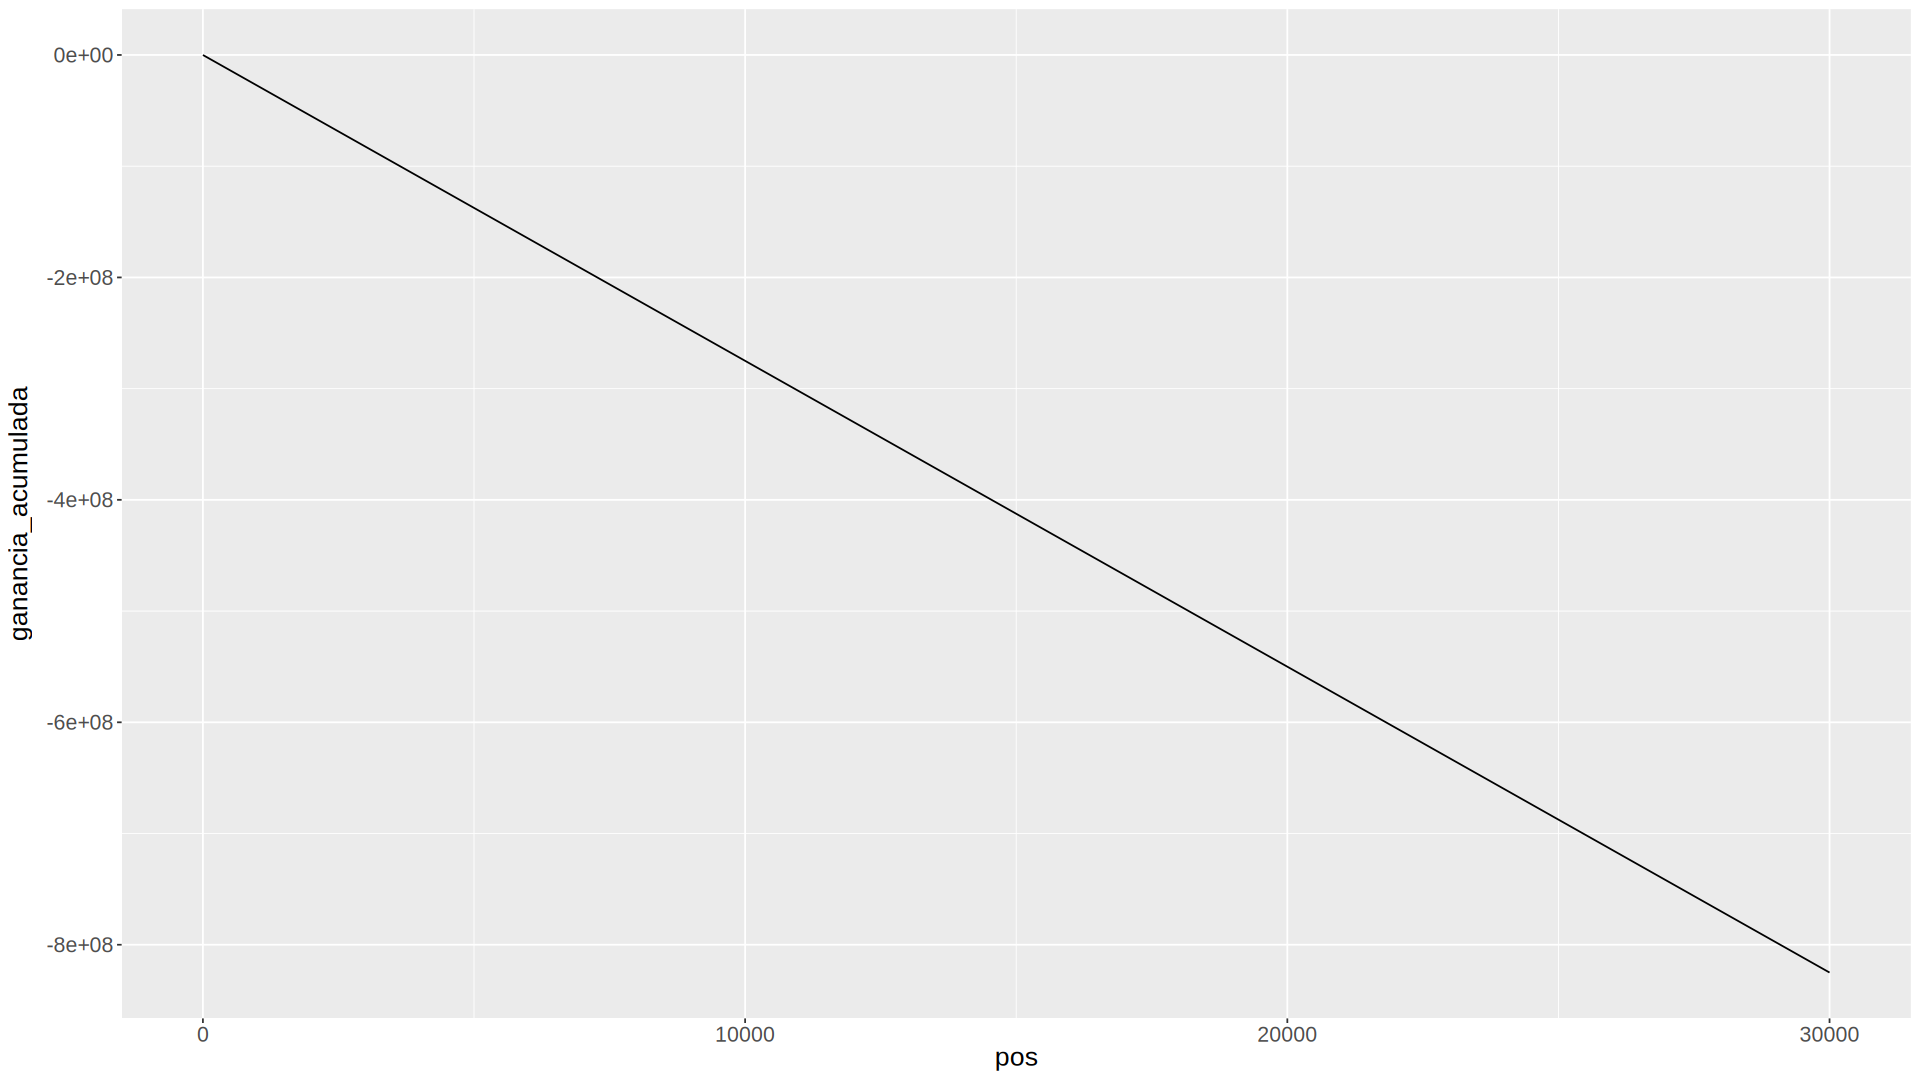

In [ ]:
# observamos la curva de ganancia
gra <- ggplot(
           data= tb_prediccion[pos <= amostrar],
           aes( x= pos, y= ganancia_acumulada)
             ) + geom_line()

gra <- gra + theme(text = element_text(size = 16))

options(repr.plot.width=16, repr.plot.height=9)
print( gra )

Revisamos ganancia bajo distintos cortes

In [ ]:
# inicilizo el dataset  drealidad
drealidad <- realidad_inicializar( dfuture, PARAM)

In [ ]:
PARAM$cortes

[1]  4000  4500  5000  5500  6000  6500  7000  7500  8000  8500  9000  9500
[13] 10000 10500 11000 11500 12000 12500 13000 13500 14000 14500 15000 15500
[25] 16000 16500 17000 17500 18000 18500 19000

In [ ]:
write_yaml( PARAM, file="PARAM.yml")

In [ ]:
format(Sys.time(), "%a %b %d %X %Y")

[1] "Sun Oct 11 03:21:25 AM 2026"

Finalmente usted deberá cargar el resultado de su corrida en la Google Sheet Colaborativa,  hoja **TareaHogar04**
<br> Siéntase libre de agregar las columnas que hagan falta a la planilla

In [ ]:
summary(tb_prediccion$prob)

     Min.   1st Qu.    Median      Mean   3rd Qu.      Max. 
2.800e-07 2.943e-05 1.145e-04 9.277e-03 7.828e-04 9.198e-01 

In [ ]:
dataset[, .N, by = .(foto_mes, tiene_baja = (clase_ternaria != "" & !is.na(clase_ternaria)))]

foto_mes,tiene_baja,N
<int>,<lgl>,<int>
202103,TRUE,162900
202104,TRUE,163284
202105,TRUE,163768
202106,TRUE,164114
202107,FALSE,163245
202108,FALSE,164647
202107,TRUE,1103


In [ ]:
setorder(tb_prediccion, -prob)

cortes_altos <- c(
  9500,
  10000, 10250, 10500, 10750,
  11000, 11250, 11500, 11750,
  12000, 12500
)

# Generar cada archivo automáticamente
for (corte in cortes_altos) {
  fwrite(
    tb_prediccion[1:corte, .(numero_de_cliente = as.integer(numero_de_cliente))],
    file = paste0("/content/MI_ENTREGA_ZULIP_", corte, ".csv"),
    col.names = FALSE,
    sep = ","
  )
  cat("Archivo generado: MI_ENTREGA_ZULIP_", corte, ".csv\n", sep = "")
}


Archivo generado: MI_ENTREGA_ZULIP_9500.csv
Archivo generado: MI_ENTREGA_ZULIP_10000.csv
Archivo generado: MI_ENTREGA_ZULIP_10250.csv
Archivo generado: MI_ENTREGA_ZULIP_10500.csv
Archivo generado: MI_ENTREGA_ZULIP_10750.csv
Archivo generado: MI_ENTREGA_ZULIP_11000.csv
Archivo generado: MI_ENTREGA_ZULIP_11250.csv
Archivo generado: MI_ENTREGA_ZULIP_11500.csv
Archivo generado: MI_ENTREGA_ZULIP_11750.csv
Archivo generado: MI_ENTREGA_ZULIP_12000.csv
Archivo generado: MI_ENTREGA_ZULIP_12500.csv
